In [ ]:
import os
import json
import subprocess
import sys
import time
from pathlib import Path

# ---- Experiment configuration ----
RUN_MODE = "full"
USE_DRIVE = True

REPO_URL = "https://github.com/Anirudh2627/Toolforge.git"
REPO_DIR = Path("/content/ToolForge")

MODEL_DEBUG = "Qwen/Qwen3-0.6B"
MODEL_MAIN = "Qwen/Qwen3-0.6B"

FORCE = False

MODEL_ID = MODEL_MAIN
EVAL_LIMIT = None
SFT_EPOCHS = 3
GRPO_ITERS = 60

# Persistent storage
from google.colab import drive
drive.mount("/content/drive")

OUT_DIR = Path("/content/drive/MyDrive/toolforge-full-run-v2")
OUT_DIR.mkdir(parents=True, exist_ok=True)

EVAL_DIR = OUT_DIR / "eval"
CKPT_DIR = OUT_DIR / "checkpoints"

EVAL_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

print(f"RUN_MODE={RUN_MODE}")
print(f"MODEL_ID={MODEL_ID}")
print(f"OUT_DIR={OUT_DIR}")

In [ ]:
import os
from pathlib import Path

# ---- edit these -----------------------------------------------------------
RUN_MODE   = "smoke"        # "smoke" (minutes, tiny budgets) | "full" (real experiment)
USE_DRIVE  = False          # True -> persist OUT_DIR on Google Drive across sessions
REPO_URL   = os.environ.get("TOOLFORGE_REPO_URL", "")   # your git remote, or "" + zip upload
REPO_DIR   = Path(os.environ.get("TOOLFORGE_REPO", "/content/ToolForge"))
MODEL_DEBUG = "Qwen/Qwen3-0.6B"    # pipeline debugging
MODEL_MAIN  = "Qwen/Qwen3-1.7B"    # main experiment (1.7B-class; needs T4 + QLoRA settings)
FORCE      = False                 # True -> ignore run_if_missing markers
# ---------------------------------------------------------------------------

MODEL_ID = MODEL_DEBUG if RUN_MODE == "smoke" else MODEL_MAIN
EVAL_LIMIT = 8 if RUN_MODE == "smoke" else None      # None -> whole split
SFT_EPOCHS = 1 if RUN_MODE == "smoke" else 3
GRPO_ITERS = 3 if RUN_MODE == "smoke" else 60

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path(os.environ.get("TOOLFORGE_OUT", "/content/drive/MyDrive/toolforge"))
else:
    OUT_DIR = Path(os.environ.get("TOOLFORGE_OUT", "/content/toolforge-outputs"))
OUT_DIR.mkdir(parents=True, exist_ok=True)
EVAL_DIR, CKPT_DIR = OUT_DIR / "eval", OUT_DIR / "checkpoints"
EVAL_DIR.mkdir(exist_ok=True); CKPT_DIR.mkdir(exist_ok=True)

import subprocess, sys, time

def sh(cmd: str, cwd: Path = REPO_DIR, check: bool = True) -> int:
    """Run a shell command with live output; fail loudly by default."""
    print(f"+ {cmd}")
    t0 = time.time()
    rc = subprocess.run(cmd, shell=True, cwd=str(cwd)).returncode
    print(f"  ({time.time() - t0:.1f}s, exit {rc})")
    if check and rc != 0:
        raise RuntimeError(f"command failed (exit {rc}): {cmd}")
    return rc

def run_if_missing(marker: Path, cmd: str) -> None:
    if marker.exists() and not FORCE:
        print(f"[skip] marker exists: {marker}  (set FORCE=True or delete it to re-run)")
    else:
        sh(cmd)

def show_metrics(run_dir: Path) -> None:
    m = json.loads((run_dir / "metrics.json").read_text())
    ci = m.get("wilson_ci") or {}
    print(f"{run_dir.name}: success {m['success_rate']:.3f} "
          f"(wilson95 [{ci.get('low', 0):.3f}, {ci.get('high', 0):.3f}]) on {m['n_tasks']} tasks")

import json
print(f"RUN_MODE={RUN_MODE}  MODEL_ID={MODEL_ID}  OUT_DIR={OUT_DIR}")

RUN_MODE=smoke  MODEL_ID=Qwen/Qwen3-0.6B  OUT_DIR=/content/toolforge-outputs


In [ ]:
!nvidia-smi || echo "NO GPU — attach a GPU runtime (⚠️ sections need one)"
import sys, shutil
print("python:", sys.version.split()[0])
total, used, free = shutil.disk_usage("/")
print(f"disk: {free / 1e9:.1f} GB free of {total / 1e9:.1f} GB")
try:
    import torch
    print("preinstalled torch:", torch.__version__, "| cuda:", torch.version.cuda,
          "| device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
except ImportError:
    print("torch not installed yet (Section 3 installs the training stack)")

Thu Oct 29 12:16:50 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
REPO_URL = "https://github.com/Anirudh2627/Toolforge.git"
REPO_DIR = Path("/content/ToolForge")

if not (REPO_DIR / "pyproject.toml").exists():
    !git clone https://github.com/Anirudh2627/Toolforge.git /content/ToolForge

%cd /content/ToolForge
!ls
sh("pip uninstall -y torchao || true")

Cloning into '/content/ToolForge'...
remote: Enumerating objects: 173, done.
remote: Counting objects: 100% (173/173), done.
remote: Compressing objects: 100% (129/129), done.
remote: Total 173 (delta 54), reused 148 (delta 33), pack-reused 0 (from 0)
Receiving objects: 100% (173/173), 304.75 KiB | 1.62 MiB/s, done.
Resolving deltas: 100% (54/54), done.
/content/ToolForge
configs  notebooks	 requirements-demo.txt	  requirements.txt
data	 pyproject.toml  requirements-dev.txt	  scripts
demo	 README.md	 requirements-report.txt  src
LICENSE  reports	 requirements-train.txt   tests
+ pip uninstall -y torchao || true
  (0.8s, exit 0)


0

In [ ]:
sh("python -c \"import torch; print(torch.__version__)\"")
sh("pip install -q -r requirements-train.txt")
sh("pip install -q -e '.[dev,report]'")
sh("pip install -q -r requirements-demo.txt || true")  # demo deps are optional here

+ python -c "import torch; print(torch.__version__)"
  (5.7s, exit 0)
+ pip install -q -r requirements-train.txt
  (9.4s, exit 0)
+ pip install -q -e '.[dev,report]'
  (5.1s, exit 0)
+ pip install -q -r requirements-demo.txt || true
  (3.9s, exit 0)


0

In [ ]:
sh("python scripts/check_train_env.py --model-id " + MODEL_ID)
sh('CUDA_VISIBLE_DEVICES="" python -m pytest tests/ -q')

+ python scripts/check_train_env.py --model-id Qwen/Qwen3-0.6B
  (13.8s, exit 0)
+ CUDA_VISIBLE_DEVICES="" python -m pytest tests/ -q
  (25.5s, exit 0)


0

In [ ]:
run_if_missing(REPO_DIR / "data/tasks/benchmark_v1.jsonl",
               "python scripts/generate_tasks.py --config configs/base.yaml")
sh("head -c 600 data/tasks/benchmark_v1.jsonl")
print()
import json as _json
print(_json.dumps(_json.loads((REPO_DIR / "data/tasks/benchmark_v1_summary.json").read_text())["by_split"], indent=2))

+ python scripts/generate_tasks.py --config configs/base.yaml
  (0.2s, exit 0)
+ head -c 600 data/tasks/benchmark_v1.jsonl
  (0.0s, exit 0)

{
  "test": 59,
  "train": 116,
  "val": 17
}


In [ ]:
_limit = f"--limit {EVAL_LIMIT}" if EVAL_LIMIT else ""
run_if_missing(EVAL_DIR / "base-smoke" / "metrics.json",
               f"python scripts/evaluate.py --policy hf --model-id {MODEL_ID} "
               f"--split test {_limit} --run-name base-smoke --out '{EVAL_DIR}'")
show_metrics(EVAL_DIR / "base-smoke")

+ python scripts/evaluate.py --policy hf --model-id Qwen/Qwen3-0.6B --split test --limit 8 --run-name base-smoke --out '/content/toolforge-outputs/eval'
  (385.0s, exit 0)
base-smoke: success 0.250 (wilson95 [0.071, 0.591]) on 8 tasks


In [ ]:
run_if_missing(REPO_DIR / "data/trajectories/reference_trainval.jsonl",
               "python scripts/generate_trajectories.py --source reference")
sh("cat data/trajectories/reference_trainval_stats.json | head -c 600")

+ python scripts/generate_trajectories.py --source reference
  (0.4s, exit 0)
+ cat data/trajectories/reference_trainval_stats.json | head -c 600
  (0.0s, exit 0)


0

In [ ]:
run_if_missing(REPO_DIR / "data/sft/sft_train.jsonl",
               "python scripts/prepare_sft_data.py "
               "--trajectories data/trajectories/reference_trainval.jsonl --catalog compact")
sh("cat data/sft/sft_stats.json")
# Serialization self-check against the REAL tokenizer (masking correctness):
sh(f"python scripts/validate_qwen3_serialization.py {MODEL_ID}")

+ python scripts/prepare_sft_data.py --trajectories data/trajectories/reference_trainval.jsonl --catalog compact
  (0.2s, exit 0)
+ cat data/sft/sft_stats.json
  (0.0s, exit 0)
+ python scripts/validate_qwen3_serialization.py Qwen/Qwen3-0.6B
  (9.3s, exit 0)


0

In [ ]:
SFT_OUT = CKPT_DIR / "sft"
_smoke = " --smoke" if RUN_MODE == "smoke" else ""
run_if_missing(SFT_OUT / "adapter-final" / "adapter_config.json",
               f"python scripts/train_sft.py --config configs/sft.yaml"
               f" --model-id {MODEL_ID} --output-dir '{SFT_OUT}'{_smoke}"
               f" --use-4bit --gradient-checkpointing --resume"
               + ("" if _smoke else f" --epochs {SFT_EPOCHS}"))

+ python scripts/train_sft.py --config configs/sft.yaml --model-id Qwen/Qwen3-0.6B --output-dir '/content/toolforge-outputs/checkpoints/sft' --smoke --use-4bit --gradient-checkpointing --resume
  (23.3s, exit 0)


In [ ]:
_limit = f"--limit {EVAL_LIMIT}" if EVAL_LIMIT else ""
ADAPTER = SFT_OUT / "adapter-final"
run_if_missing(EVAL_DIR / "sft-val" / "metrics.json",
               f"python scripts/evaluate.py --policy hf --model-id {MODEL_ID} "
               f"--adapter-id '{ADAPTER}' --split val --compact-catalog "
               f"--run-name sft-val --out '{EVAL_DIR}'")
show_metrics(EVAL_DIR / "sft-val")

+ python scripts/evaluate.py --policy hf --model-id Qwen/Qwen3-0.6B --adapter-id '/content/toolforge-outputs/checkpoints/sft/adapter-final' --split val --compact-catalog --run-name sft-val --out '/content/toolforge-outputs/eval'
  (1584.9s, exit 0)
sft-val: success 0.353 (wilson95 [0.173, 0.587]) on 17 tasks


In [ ]:
GRPO_OUT = CKPT_DIR / "grpo"
assert ADAPTER and Path(ADAPTER).exists(), "Run Sections 9-10 (SFT) before GRPO"
if RUN_MODE == "smoke":
    run_if_missing(GRPO_OUT / "history.jsonl",
                   f"python scripts/train_grpo.py --config configs/grpo.yaml --smoke "
                   f"--model-id {MODEL_ID} --adapter-id '{ADAPTER}' --output-dir '{GRPO_OUT}' "
                   f"--compact-catalog --tasks-file {REPO_DIR}/data/tasks/benchmark_v1.jsonl")
    sh(f"tail -n 2 {GRPO_OUT}/history.jsonl || true")
else:
    print("Full GRPO runs in Section 12.")

[skip] marker exists: /content/toolforge-outputs/checkpoints/grpo/history.jsonl  (set FORCE=True or delete it to re-run)
+ tail -n 2 /content/toolforge-outputs/checkpoints/grpo/history.jsonl || true
  (0.0s, exit 0)


In [ ]:
if RUN_MODE == "full":
    sh(
        f"python scripts/train_grpo.py --config configs/grpo.yaml "
        f"--model-id {MODEL_ID} --adapter-id '{ADAPTER}' "
        f"--output-dir '{GRPO_OUT}' "
        f"--compact-catalog --resume --iterations {GRPO_ITERS} "
        f"--tasks-file {REPO_DIR}/data/tasks/benchmark_v1.jsonl"
    )

    if (GRPO_OUT / "history.jsonl").exists():
        sh(f"tail -n 5 {GRPO_OUT}/history.jsonl")
    else:
        raise RuntimeError("GRPO finished without producing history.jsonl")
else:
    raise RuntimeError("This experiment must run in full mode.")

Smoke mode: full GRPO skipped (set RUN_MODE='full' in Section 0).


In [ ]:
_limit = f"--limit {EVAL_LIMIT}" if EVAL_LIMIT else ""
GRPO_CKPT = sorted((GRPO_OUT).glob("checkpoint-iter*"))
GRPO_CKPT = GRPO_CKPT[-1] if GRPO_CKPT else ADAPTER  # fall back to SFT if GRPO absent

run_if_missing(EVAL_DIR / "test-base" / "metrics.json",
               f"python scripts/evaluate.py --policy hf --model-id {MODEL_ID} --split test "
               f"{_limit} --compact-catalog --run-name test-base --out {EVAL_DIR}")
run_if_missing(EVAL_DIR / "test-sft" / "metrics.json",
               f"python scripts/evaluate.py --policy hf --model-id {MODEL_ID} "
               f"--adapter-id '{ADAPTER}' --split test {_limit} --compact-catalog "
               f"--run-name test-sft --out '{EVAL_DIR}'")
run_if_missing(EVAL_DIR / "test-grpo" / "metrics.json",
               f"python scripts/evaluate.py --policy hf --model-id {MODEL_ID} "
               f"--adapter-id '{GRPO_CKPT}' --split test {_limit} --compact-catalog "
               f"--run-name test-grpo --out '{EVAL_DIR}'")
for name in ("test-base", "test-sft", "test-grpo"):
    if (EVAL_DIR / name / "metrics.json").exists():
        show_metrics(EVAL_DIR / name)

+ python scripts/evaluate.py --policy hf --model-id Qwen/Qwen3-0.6B --split test --limit 8 --compact-catalog --run-name test-base --out /content/toolforge-outputs/eval
  (303.0s, exit 0)
+ python scripts/evaluate.py --policy hf --model-id Qwen/Qwen3-0.6B --adapter-id '/content/toolforge-outputs/checkpoints/sft/adapter-final' --split test --limit 8 --compact-catalog --run-name test-sft --out '/content/toolforge-outputs/eval'
  (428.7s, exit 0)
+ python scripts/evaluate.py --policy hf --model-id Qwen/Qwen3-0.6B --adapter-id '/content/toolforge-outputs/checkpoints/grpo/checkpoint-iter00001' --split test --limit 8 --compact-catalog --run-name test-grpo --out '/content/toolforge-outputs/eval'
  (431.0s, exit 0)
test-base: success 0.250 (wilson95 [0.071, 0.591]) on 8 tasks
test-sft: success 0.500 (wilson95 [0.215, 0.785]) on 8 tasks
test-grpo: success 0.500 (wilson95 [0.215, 0.785]) on 8 tasks


+ python scripts/compare_models.py --run base='/content/toolforge-outputs/eval/test-base' --run sft='/content/toolforge-outputs/eval/test-sft' --run sft-grpo='/content/toolforge-outputs/eval/test-grpo' --history sft-grpo='/content/toolforge-outputs/checkpoints/grpo/history.jsonl' --out '/content/toolforge-outputs/ablations'
  (1.9s, exit 0)


# ToolForge Ablation Report

_Generated 2026-10-29T16:21:12Z from saved evaluation artifacts only. No number in this
report was produced by anything other than the runs listed below._

## Runs compared

| label | model | split | n tasks | grammar | success (wilson95) |
|---|---|---|---|---|---|
| base | hf:Qwen/Qwen3-0.6B | test | 8 | tf-gram-v1 | **0.250** [0.071, 0.591] |
| sft | hf:Qwen/Qwen3-0.6B+adapter:/content/toolforge-outputs/checkpoints/sft/adapter-final | test | 8 | tf-gram-v1 | **0.500** [0.215, 0.785] |
| sft-grpo | hf:Qwen/Qwen3-0.6B+adapter:/content/toolforge-outputs/checkpoints/grpo/checkpoint-iter00001 | test | 8 | tf-gram-v1 | **0.500** [0.215, 0.785] |

## Headline

- Strongest run: **sft** at 0.500 success rate.
- The gap to `sft-grpo` is **not statistically distinguishable** (Wilson 95% intervals overlap) at these sample sizes.

## Seen vs held-out tool families

| label | seen success | held-out success | gap |
|---|---|---|---|
| base | 0.250 | n/a | n/a |
| sft | 0.500 | n/a | n/a |
| sft-grpo | 0.500 | n/a | n/a |

## Behavior rates

| label | invalid JSON | invalid tool call | arg validation | step limit | side effects | clarify P/R |
|---|---|---|---|---|---|---|
| base | 0.429 | 0.643 | 0.000 | 0.125 | 0.250 | n/a/0.000 |
| sft | 0.235 | 0.500 | 0.167 | 0.125 | 0.125 | 0.500/0.500 |
| sft-grpo | 0.235 | 0.500 | 0.167 | 0.125 | 0.125 | 0.500/0.500 |

## Latency (measured in the evaluation runs)

| label | policy s median | policy s p95 | wall s median | time-to-success wall median |
|---|---|---|---|---|
| base | 38.468 | 62.863 | 38.469 | 14.041 |
| sft | 39.059 | 141.898 | 39.059 | 27.493 |
| sft-grpo | 39.381 | 141.687 | 39.382 | 27.465 |

## Paired task analysis (intersection of task sets)

- `base` vs `sft` on 8 tasks: both 2, only-base 0, only-sft 2, neither 4; exact McNemar p = 0.5000
- `sft` vs `sft-grpo` on 8 tasks: both 4, only-sft 0, only-sft-grpo 0, neither 4; exact McNemar p = 1.0000

## Repeated-training variability

- Not available: each configuration was trained once. Run-to-run training
  variability is therefore NOT captured; per-run CIs are bootstrap over tasks only.

## RL dynamics (training reward vs validated accuracy)

- `sft-grpo`: 2 iterations, 1 validated evals, no divergence warnings.

## Regressions (drops > threshold between consecutive runs)

- None beyond the configured threshold.

## Top failure categories per run

- `base`: state_check_failed (3), missing_clarification (2), forbidden_state_change (2), step_limit_exceeded (1), answer_check_failed (1)
- `sft`: state_check_failed (3), missing_clarification (1), forbidden_state_change (1), unnecessary_clarification (1), step_limit_exceeded (1)
- `sft-grpo`: state_check_failed (3), missing_clarification (1), forbidden_state_change (1), unnecessary_clarification (1), step_limit_exceeded (1)

## Limitations

- Sample sizes above are the whole story for statistical power; overlapping CIs
  mean differences must not be over-interpreted.
- Retrieval/refusal categories are verified lexically (computed ground-truth
  containment); state-change categories are verified from environment state.
- Latency numbers are from the evaluation machines recorded in each run's
  run_config.json; hardware may differ between runs — check before comparing.
- This report reflects ONLY the supplied runs; nothing is imputed.


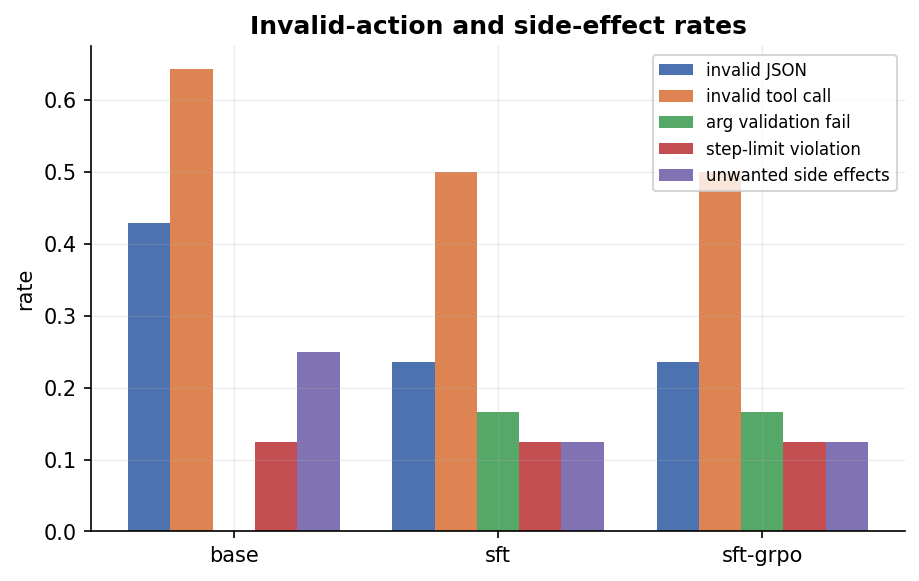

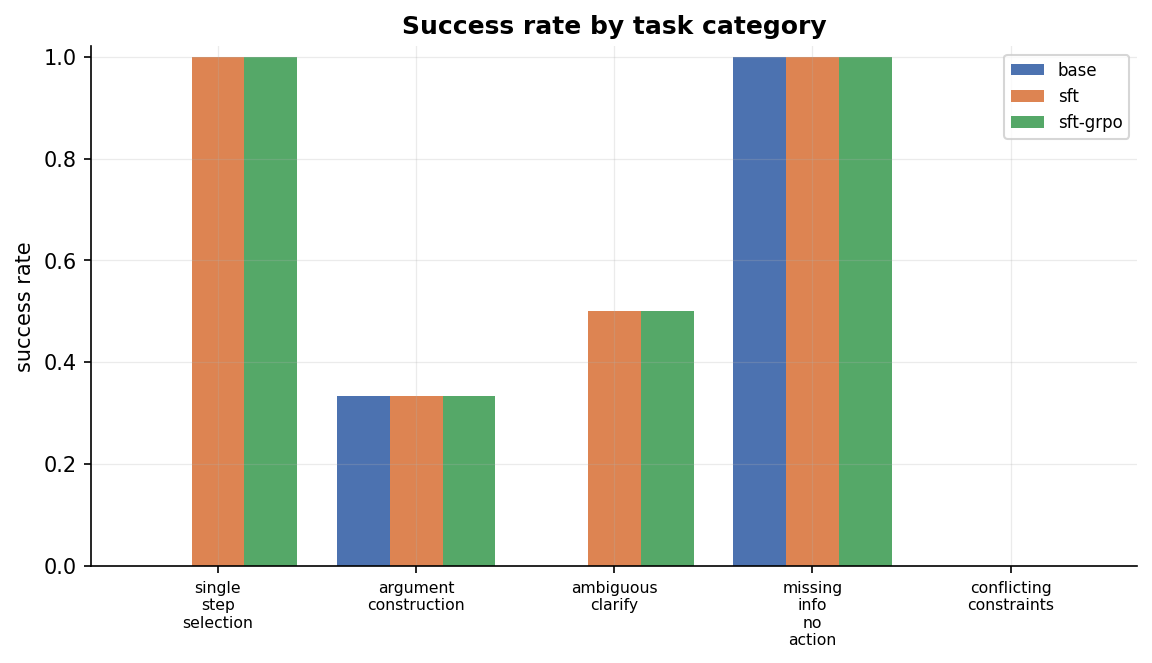

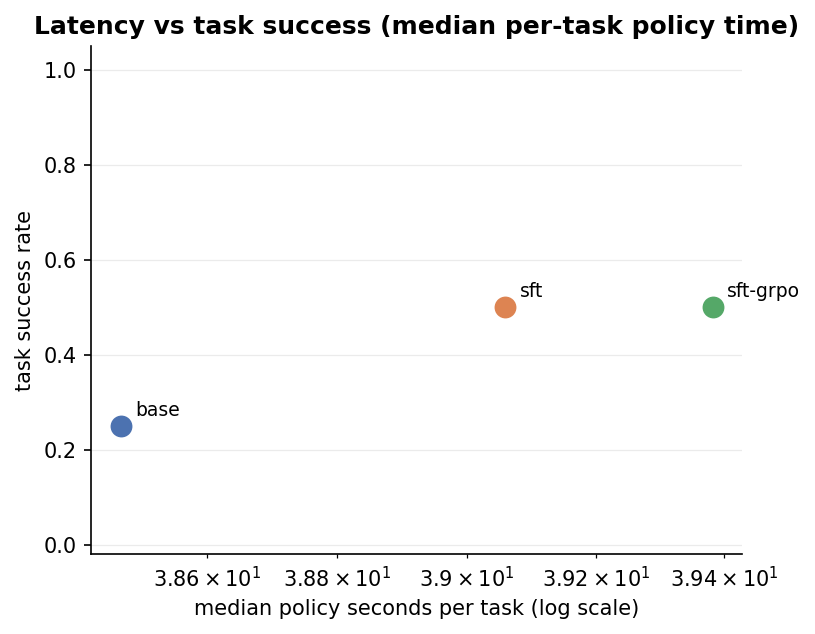

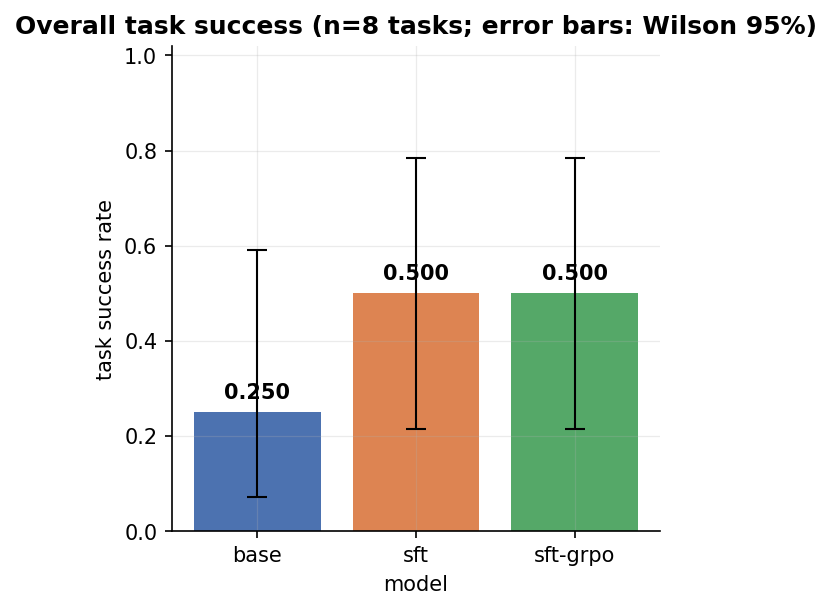

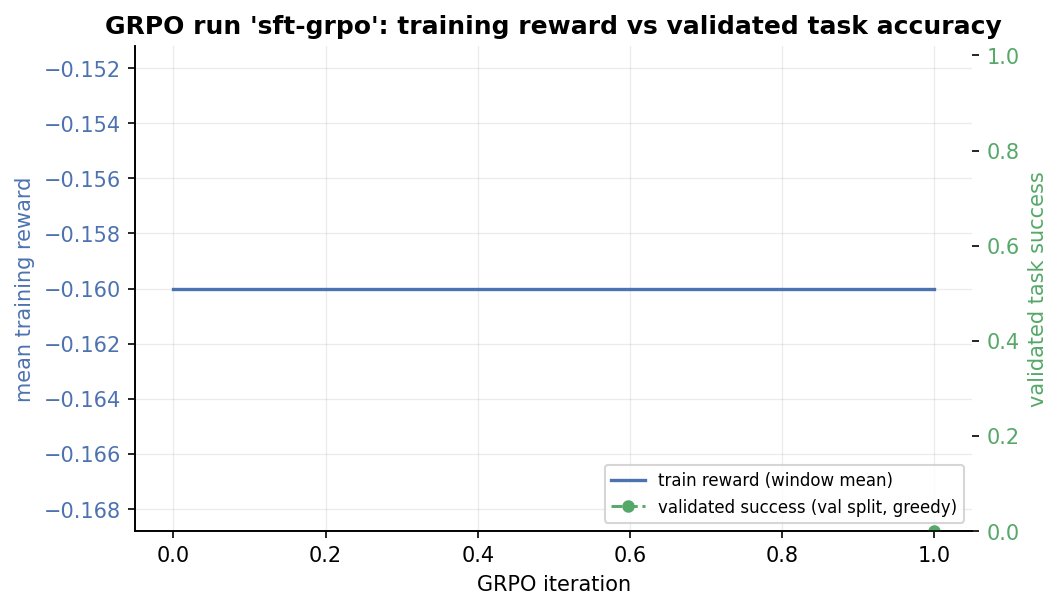

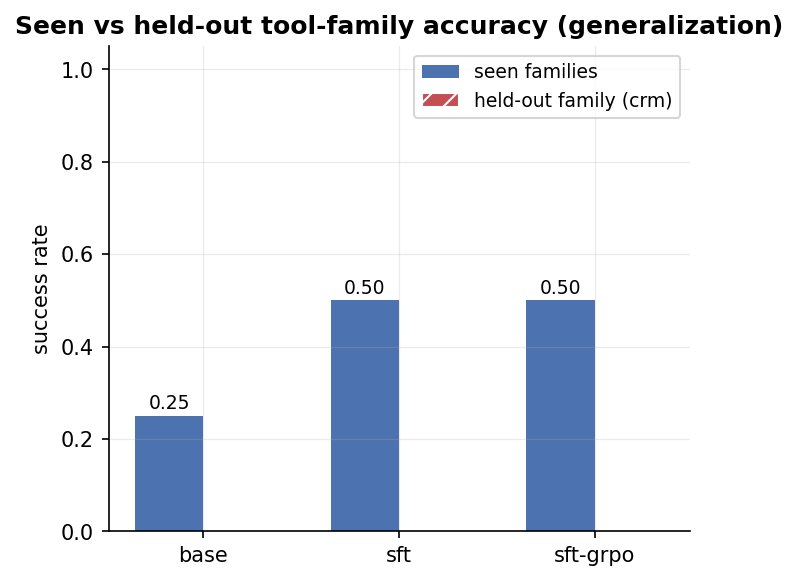

In [ ]:
_runs = []
for label, name in (("base", "test-base"), ("sft", "test-sft"), ("sft-grpo", "test-grpo")):
    if (EVAL_DIR / name / "metrics.json").exists():
        _runs.append(f"--run {label}='{EVAL_DIR / name}'")
if len(_runs) >= 2:
    _hist = f"--history sft-grpo='{GRPO_OUT}/history.jsonl'" if (GRPO_OUT / "history.jsonl").exists() else ""
    _abl = OUT_DIR / "ablations"
    sh("python scripts/compare_models.py " + " ".join(_runs) + f" {_hist} --out '{_abl}'")
    from IPython.display import Markdown, Image, display
    display(Markdown((OUT_DIR / "ablations" / "REPORT.md").read_text()[:4000]))
    for png in sorted((OUT_DIR / "ablations" / "plots").glob("*.png")):
        display(Image(filename=str(png)))
else:
    print("Need at least two evaluated checkpoints (Section 13) before comparing.")

In [ ]:
_bout = OUT_DIR / "benchmark.json"
_n_bench = 4 if RUN_MODE == "smoke" else 12
sh(f"python scripts/benchmark_inference.py --policy hf --model-id {MODEL_ID} "
   f"--adapter-id '{GRPO_CKPT}' --n-tasks {_n_bench} --ttft --out '{_bout}'")
# To get a labeled cost estimate, append e.g.:
#   --gpu-cost-per-hour 0.35 --hardware-label "rented T4 (vast.ai)"
import json as _j
_bench = OUT_DIR / "benchmark.json"
_b = _j.loads(_bench.read_text()) if _bench.exists() else None
print("peak GPU bytes:", (_b or {}).get("gpu_peak_memory_bytes"))

NameError: name 'OUT_DIR' is not defined

In [ ]:
# Optional merged export (skip on smoke to save disk/time):
if RUN_MODE == "full":
    _mout = OUT_DIR / "merged-sft"
    run_if_missing(_mout / "config.json",
                   f"python scripts/export_model.py --adapter '{ADAPTER}' "
                   f"--base-model {MODEL_ID} --out '{_mout}'")

if not USE_DRIVE:
    print("⚠️ USE_DRIVE=False: everything under OUT_DIR lives on the ephemeral Colab VM.\n"
          "Download what matters (adapters, metrics, predictions, history) via the file "
          "panel,\nor re-run Section 0 with USE_DRIVE=True before your next long stage.")
sh(f"du -sh '{OUT_DIR}'/* 2>/dev/null | sort -h | tail -12", cwd=Path("/content"))
print("\nKeep: eval/*/metrics.json + predictions.jsonl, checkpoints/*/adapter-final, "
      "grpo history.jsonl, ablations/ — these are the reproducible record of the run.")

NameError: name 'RUN_MODE' is not defined

In [ ]:
PUBLISH = False   # <-- set True only if you intend to publish
if PUBLISH:
    import getpass
    HF_USER = input("HF username: ").strip()
    HF_TOKEN = getpass.getpass("HF token (input hidden): ")
    sh("pip install -q huggingface_hub")
    from huggingface_hub import login, create_repo, upload_folder, upload_file
    login(token=HF_TOKEN, new_session=False)
    for name, folder in ((f"{HF_USER}-toolforge-sft-adapter", ADAPTER),
                         (f"{HF_USER}-toolforge-grpo-adapter", GRPO_CKPT)):
        create_repo(name, repo_type="model", exist_ok=True)
        upload_folder(folder_path=str(folder), repo_id=name,
                      ignore_patterns=["optimizer*", "rng_state*", "*.pt"])
        print("uploaded model:", name)
    create_repo(f"{HF_USER}-toolforge-benchmark", repo_type="dataset", exist_ok=True)
    upload_file(path_or_fileobj=str(REPO_DIR / "data/tasks/benchmark_v1.jsonl"),
                path_in_repo="benchmark_v1.jsonl",
                repo_id=f"{HF_USER}-toolforge-benchmark", repo_type="dataset")
    print("uploaded dataset: benchmark_v1.jsonl")
else:
    print("Publishing disabled (PUBLISH = False). Nothing was uploaded.")

Publishing disabled (PUBLISH = False). Nothing was uploaded.
